# MORA 출력 보정기 작동 해설

**과거 입력·기준 점예측 → 구간 평균 추정 → 2단계 보정 → 검증 calibration → 보정 점예측**

대상: `ts_forecaster_lib_v2` · 작성일: 2026-11-20

논문 수식을 직접 구현한 `forecast_adapters/MORA`를 셀별로 확인하는 노트북.
기존 모델의 소스·가중치·학습 경로는 변경하지 않는 구성.

> 저자 저장소 코드 미복사. 이 노트북은 합성 계산 검증이며 논문 benchmark 재현이나 실제 부품 성능의 증거와 구분.
> 실제 데이터·DB·외부 API·기준 모델 학습을 사용하지 않는 실행.


## 목표와 범위

| 질문 | 관찰할 대상 |
|---|---|
| 무엇을 보정하는가? | 원본 점예측에 추가되는 보정량 |
| 미래 정답을 추론에서 보는가? | `ForecastQuery`와 적합 전용 `ForecastFitData`의 분리 |
| 27주를 어떻게 요약하는가? | 6개 구간 평균과 첫 위치를 보존하는 기저 |
| 적합 과정에서 시간을 어떻게 분리하는가? | purged OOF·nested reliability와 별도 calibration |
| 결과를 다시 사용할 수 있는가? | NPZ 저장·해시·재로딩 예측 일치 |

이번 구현은 compact 78개 특징, 두 외삽, channel-wise ridge, 2단계 보정과 검증 scale 지원.
Harmonic template·factorized estimator·확장 특징·논문 전체 설정 탐색은 미포함.
첫 예측값 보존은 원래 첫 예측을 유지한다는 뜻이며, 마지막 관측값으로 바꾸는 동작과 구분.


## 실행 준비

저장소 안에서 커널을 시작하고 위에서부터 전체 실행.
NumPy·SciPy는 프로젝트 기본 의존성. 외부 `mora` 패키지는 필요하지 않는 구성.
프로젝트 기본 의존성인 PyTorch 자체를 제거하는 작업은 아닌 범위.

```bash
# 필요한 경우 별도 개발 환경에서 설치. 이 노트북은 설치를 실행하지 않는 구성.
python -m pip install -e '.[notebook,dev]'
```

재실행 시에는 같은 seed의 새 합성 자료와 보정기를 생성하는 구성.
저장 실습은 임시 디렉토리만 사용하며 완료 후 자동 정리.


In [1]:
from pathlib import Path
from dataclasses import replace
from importlib.metadata import version
import inspect
import sys
import tempfile

roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
REPO_ROOT = next((path for path in roots
                  if (path / "src/modeling_module/forecast_adapters/MORA").is_dir()
                  and (path / "pyproject.toml").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("ts_forecaster_lib 저장소 내부에서 커널을 시작해야 합니다.")
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("현재 Python:", sys.executable)
display(pd.DataFrame({"라이브러리": ["numpy", "scipy", "pandas"],
                      "버전": [version(name) for name in ("numpy", "scipy", "pandas")]}))


Matplotlib is building the font cache; this may take a moment.


현재 Python: /private/tmp/ts-forecaster-chronos2-native-env-20261119/bin/python


,라이브러리,버전
0,numpy,2.1.3
1,scipy,1.15.2
2,pandas,2.3.3


### 독립 모듈과 실험 설정

`MORAAdapter`는 모델 객체가 아닌 과거 배열과 기준 예측 배열을 받는 연결 모듈.
아래 period 13·rank 12는 합성 검증 설정이며 주간 부품 데이터의 운영 최적값과 구분.
기본 `single_series`에서는 서로 다른 부품을 자동으로 섞지 않는 계약.


In [2]:
from modeling_module.forecast_adapters import contracts
from modeling_module.forecast_adapters.contracts import ForecastQuery, ForecastFitData
from modeling_module.forecast_adapters.MORA import MORAAdapter, MORAConfig
from modeling_module.forecast_adapters.MORA.fitting import purged_folds
from modeling_module.forecast_adapters.MORA.native.basis import coarse_operator, tapered_basis
from modeling_module.forecast_adapters.MORA.native.features import compact_features
from modeling_module.forecast_adapters.MORA.native.stagewise import fit_mapping
from model_test.mora.synthetic import make_synthetic, point_metrics

SEED = 42
config = MORAConfig(lookback=52, horizon=27, period=13, correction_rank=12)
display(pd.DataFrame([{"과거 L": config.lookback, "예측 H": config.horizon,
                       "구간 Q": config.coarse_count, "보정 rank": config.correction_rank,
                       "OOF 블록": config.folds, "scope": config.scope}]))


,과거 L,예측 H,구간 Q,보정 rank,OOF 블록,scope
0,52,27,6,12,4,single_series


## 1. 합성 자료와 기준 예측

추세와 주기·작은 잡음을 가진 연속 시계열의 서로 겹치지 않는 창 생성.
기준 예측은 과거 평균에서 8을 뺀 값의 반복이며 미래 정답은 읽지 않는 계산.
일정한 과소 예측을 의도적으로 넣어 보정 경로를 관찰하기 쉽게 만든 자료.

학습 96개 → 검증 24개 → 시험 24개 query를 시간순으로 분리.
두 채널은 같은 합성 시계열의 고정된 신호이며 서로 다른 부품을 채널로 임의 합친 의미와 구분.
가로축의 origin은 연속 정수 위치이고 `YYYYWW` 값을 직접 더한 숫자가 아닌 계약.


In [3]:
train, validation, test = make_synthetic(config, seed=SEED)
display(pd.DataFrame([
    {"구분": name, "query 수": len(data.target), "history shape": str(data.query.history.shape),
     "target shape": str(data.target.shape), "첫 정답 위치": int(data.query.origins.min()),
     "마지막 정답 위치": int(data.query.origins.max() + config.horizon - 1)}
    for name, data in (("학습", train), ("검증", validation), ("시험", test))
]))
assert train.query.origins.max() + config.horizon - 1 < validation.query.origins.min()
assert validation.query.origins.max() + config.horizon - 1 < test.query.origins.min()
original_base = test.query.backbone_prediction.copy()


,구분,query 수,history shape,target shape,첫 정답 위치,마지막 정답 위치
0,학습,96,"(96, 52, 2)","(96, 27, 2)",52,7583
1,검증,24,"(24, 52, 2)","(24, 27, 2)",7636,9479
2,시험,24,"(24, 52, 2)","(24, 27, 2)",9532,11375


### 시험 query 하나의 보정 전 모습

과거 52개 관측과 그 뒤의 27개 정답, 기준 예측을 같은 단위로 비교하는 그림.
시험 정답은 이 그림과 마지막 오차 계산에서만 사용하는 자료이며 적합 입력에는 미포함.
실제 모델을 호출한 결과가 아니라 의도적으로 편향시킨 합성 baseline이라는 조건.


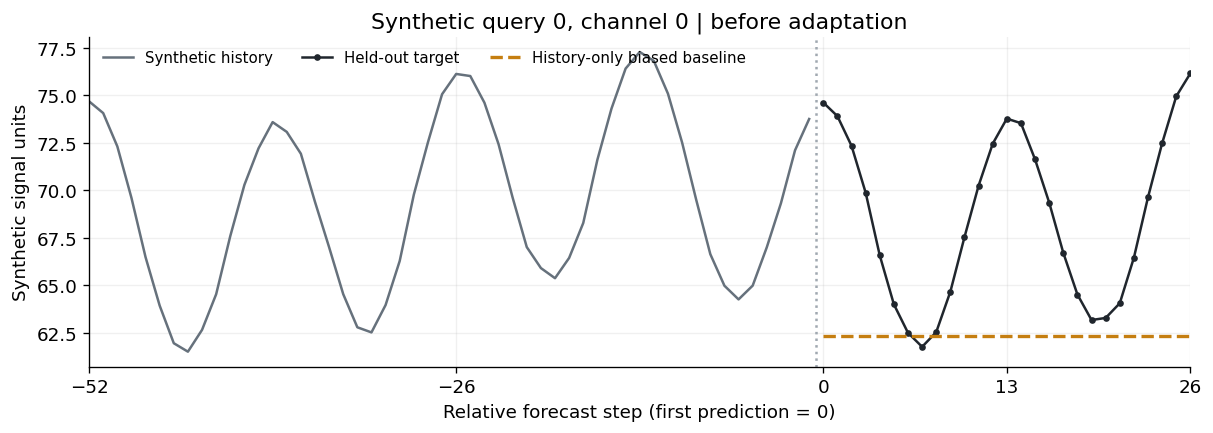

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
ax.plot(np.arange(-config.lookback, 0), test.query.history[0, :, 0],
        color="#66717c", label="Synthetic history")
ax.plot(np.arange(config.horizon), test.target[0, :, 0], color="#20262d", marker="o",
        markersize=3, label="Held-out target")
ax.plot(np.arange(config.horizon), original_base[0, :, 0], color="#c57e10",
        linestyle="--", linewidth=2, label="History-only biased baseline")
ax.axvline(-0.5, color="#a0a8b0", linestyle=":")
ax.set(title="Synthetic query 0, channel 0 | before adaptation", xlim=(-52, 26),
       xticks=[-52, -26, 0, 13, 26], xlabel="Relative forecast step (first prediction = 0)",
       ylabel="Synthetic signal units")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left")
ax.grid(alpha=0.18)
plt.show()


## 2. 미래 구간 평균과 보정 기저

H27을 6개의 겹치지 않는 구간으로 분할해 구간별 평균을 계산하는 연산자가 A.
U는 낮은 주파수의 cosine 모드를 시작 경계에서 줄인 뒤 QR로 직교화한 보정 기저.

\[
q=Ay,\qquad U^TU=I,\qquad U_{0,:}=0
\]

U의 첫 행이 정확히 0이므로 어떤 보정 계수라도 첫 예측 위치의 보정량은 0.
이 제약 때문에 첫 위치 오차는 그대로 남을 수 있는 구조.


,구간,시작 step,종료 step,관측 수
0,0,0,4,5
1,1,5,9,5
2,2,10,14,5
3,3,15,18,4
4,4,19,22,4
5,5,23,26,4


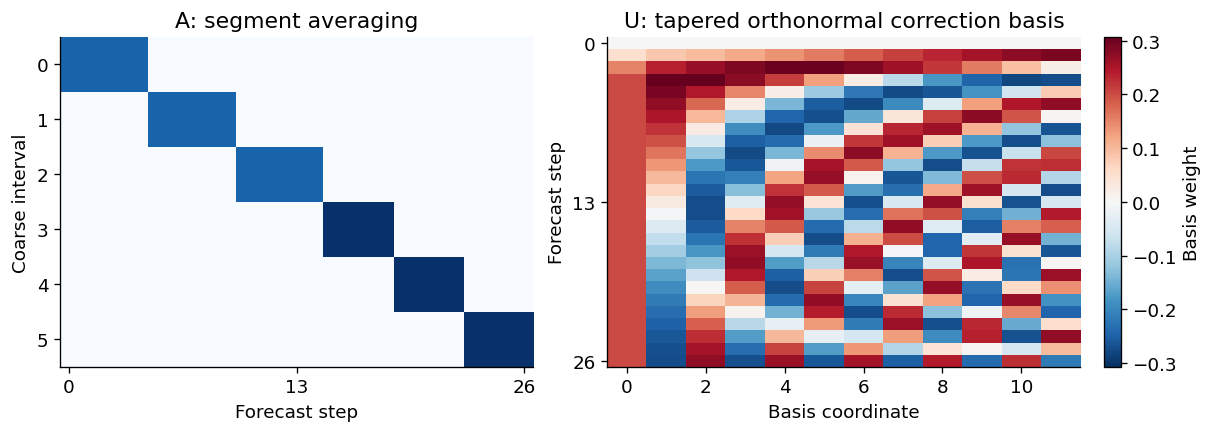

In [5]:
A = coarse_operator(config.horizon, config.coarse_count)
U = tapered_basis(config.horizon, config.correction_rank, config.taper_steps)
np.testing.assert_allclose(A.sum(axis=1), 1)
np.testing.assert_allclose(U.T @ U, np.eye(config.correction_rank), atol=1e-12)
np.testing.assert_array_equal(U[0], 0)
display(pd.DataFrame([{"구간": row, "시작 step": int(np.flatnonzero(values)[0]),
                       "종료 step": int(np.flatnonzero(values)[-1]), "관측 수": int(np.count_nonzero(values))}
                      for row, values in enumerate(A)]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].imshow(A, aspect="auto", cmap="Blues", vmin=0)
axes[0].set(title="A: segment averaging", xlabel="Forecast step", ylabel="Coarse interval",
            xticks=[0, 13, 26])
image = axes[1].imshow(U, aspect="auto", cmap="RdBu_r", vmin=-np.abs(U).max(), vmax=np.abs(U).max())
axes[1].set(title="U: tapered orthonormal correction basis", xlabel="Basis coordinate", ylabel="Forecast step",
            yticks=[0, 13, 26])
fig.colorbar(image, ax=axes[1], label="Basis weight")
plt.show()


## 3. 과거 특징과 미래 평균 추정

Compact 특징은 DCT 16개, 전체 통계 8개, 블록 평균 12개, 최근 변화 36개, 시간 인코딩 6개로 총 78개.
과거 관측과 이미 알려진 origin의 시간 위치만 사용하며 정답은 특징 추출 인자에 없는 구성.
별도 ridge가 미래 구간 평균 자체를 추정하고 기존 예측과 비교할 때 잔차 신호로 전환하는 방식.

원 단위와 마지막 관측을 뺀 상대 단위 두 관점의 추정치를 원 단위로 복원해 평균하는 구성.
정규화 평균·표준편차는 각 OOF 학습 자료 안에서만 계산.


In [6]:
features = compact_features(train.query.history, train.query.origins, config.period)
assert features.shape == (96, 2, 78)
display(pd.DataFrame([
    {"특징 구분": "DCT", "개수": 16}, {"특징 구분": "전체 통계", "개수": 8},
    {"특징 구분": "블록 평균", "개수": 12}, {"특징 구분": "최근 변화", "개수": 36},
    {"특징 구분": "시간 인코딩", "개수": 6},
]))
print("실제 특징 shape:", features.shape)
print("특징 함수 인자:", inspect.signature(compact_features))


,특징 구분,개수
0,DCT,16
1,전체 통계,8
2,블록 평균,12
3,최근 변화,36
4,시간 인코딩,6


실제 특징 shape: (96, 2, 78)
특징 함수 인자: (history, origins, period)


## 4. 시간 중첩을 제거하는 OOF

무작위 K-fold로 인접 창을 섞으면 held 정답이 다른 창의 과거 입력으로 나타날 수 있는 문제.
따라서 같은 시계열에서 held raw 구간 `[origin-L, origin+H-1]`과 겹치는 창은 모두 제외.
2단계 gain 추정은 outer held 정답을 내부 coarse·gain·매핑에 사용하지 않는 nested OOF.

이 합성 예제는 애초 창 간격이 L+H이므로 held 블록 외의 창을 추가로 버릴 필요가 없는 구성.
아래 두 번째 표는 촘촘히 겹치는 창에서는 추가 제외가 발생한다는 별도 계약 시연.


In [7]:
folds = purged_folds(train.query, config.folds, config.min_fold_train)
display(pd.DataFrame([{"fold": i, "적합 query": len(fit), "held query": len(held),
                       "held 첫 origin": int(train.query.origins[held].min()),
                       "held 마지막 origin": int(train.query.origins[held].max())}
                      for i, (fit, held) in enumerate(folds)]))
dense = ForecastQuery(np.ones((100, 24, 1)), np.ones((100, 8, 1)), np.arange(100) * 3 + 24,
                      ("demo",), ("dense_demo",) * 100, "split_demo_only")
dense_folds = purged_folds(dense, 4, 8)
rows = []
for i, (fit, held) in enumerate(dense_folds):
    starts, ends = dense.origins - 24, dense.origins + 7
    assert np.all((ends[fit] < starts[held].min()) | (starts[fit] > ends[held].max()))
    rows.append({"dense fold": i, "held 외 query": 100 - len(held),
                 "purge 후 적합 query": len(fit), "중첩 추가 제외": 100 - len(held) - len(fit)})
display(pd.DataFrame(rows))


,fold,적합 query,held query,held 첫 origin,held 마지막 origin
0,0,72,24,52,1869
1,1,72,24,1948,3765
2,2,72,24,3844,5661
3,3,72,24,5740,7557


,dense fold,held 외 query,purge 후 적합 query,중첩 추가 제외
0,0,75,65,10
1,1,75,55,20
2,2,75,55,20
3,3,75,65,10


## 5. 적합과 2단계 보정

첫 단계는 현재 수준·최근 패턴 외삽과 기준 예측의 구간 평균 차이를 보정 계수로 변환.
두 번째 단계는 첫 보정을 적용한 뒤에도 남은 차이를 learned coarse estimate로 보완.

\[
\hat z_e=G_e K_e(m_e-A_e\hat y_0),\quad
\hat z_l=G_l K_l[m_l-A(\hat y_0+U\hat z_e)],\quad
\hat y=\hat y_0+US(\hat z_e+\hat z_l)
\]

K와 G는 학습 자료로 적합하고, S만 검증 정답으로 적합.
기준 모델 객체는 입력하지 않으므로 이 호출이 모델 가중치를 갱신하는 경로는 없음.
정규화 강도는 고정 실험 설정이며 전체 후보 탐색을 실행한 상태는 아닌 구분.


In [8]:
adapter = MORAAdapter(config).fit(train, validation)
diagnostics = adapter.diagnostics
display(pd.DataFrame(diagnostics["calibration_details"]))
print("구현:", diagnostics["implementation"])
print("원본 코드 복사:", diagnostics["source_code_copied"])
print("nested OOF:", diagnostics["second_gain_nested_crossfit"])
print("원본 모델 학습 대신 받은 자료:", diagnostics["train_provenance"])


,channel,uncorrected_objective,calibrated_objective,group_scales
0,0,0.500079,0.040746,"[1.003820319084436, 1.005871726650974, 0.96636..."
1,1,0.499923,0.040820,"[1.0011067841599333, 1.0059425025971789, 0.966..."


구현: paper_independent_v1
원본 코드 복사: False
nested OOF: True
원본 모델 학습 대신 받은 자료: synthetic_history_only


### 실제 Raw source 관찰

아래 코드는 설명용 가짜 코드가 아니라 현재 실행한 내부 연산 메서드.
비중심 모멘트와 shrinkage, 정규화된 선형 시스템을 확인하는 셀.
역행렬을 직접 만들지 않고 `solve`로 매핑을 구하는 구현.


In [9]:
source_file = Path(inspect.getfile(fit_mapping)).resolve()
print("실제 소스:", source_file.relative_to(REPO_ROOT))
display(Markdown("```python\n" + inspect.getsource(fit_mapping) + "\n```"))


실제 소스: src/modeling_module/forecast_adapters/MORA/native/stagewise.py


```python
def fit_mapping(discrepancy, target, geometry, config):
    n, channels, width = discrepancy.shape
    result = []
    for channel in range(channels):
        d, z = discrepancy[:, channel], target[:, channel]
        rms = np.sqrt(np.mean(d**2, axis=1))
        floor = max(1e-5, float(np.quantile(rms, 0.1)))
        weight = np.maximum(rms, floor) ** (-2 * config.weight_power)
        eta = d - z @ geometry.T
        zz = _shrink(z.T @ (weight[:, None] * z) / n, config.shrinkage)
        noise = _shrink(eta.T @ (weight[:, None] * eta) / n, config.shrinkage)
        dd = d.T @ (weight[:, None] * d) / n
        zd = z.T @ (weight[:, None] * d) / n
        mix = config.structured_mix
        covariance = (1 - mix) * (geometry @ zz @ geometry.T + config.noise_scale * noise) + mix * dd
        numerator = (1 - mix) * zz @ geometry.T + mix * zd
        epsilon = 1e-6 * max(float(np.trace(covariance)) / width, 1e-12)
        result.append(np.linalg.solve(covariance + epsilon * np.eye(width), numerator.T).T)
    mapping = np.stack(result)
    if not np.isfinite(mapping).all():
        raise ValueError("잔차 매핑이 유한하지 않습니다.")
    return mapping

```

## 6. 정답 없이 추론하고 시험 오차 계산

`predict`에는 query만 전달하고, 반환된 뒤 별도의 평가 단계에서 정답과 비교.
반환값은 보정 점예측·기준 점예측·보정량을 각각 유지.
기존 모델의 P10/P90이나 P50의 분위수 의미까지 보정·검증한 결과와 구분.
음수 절단이나 분위수 재정렬은 자동 수행하지 않는 계약.


In [10]:
forecast = adapter.predict(test.query)
np.testing.assert_array_equal(original_base, test.query.backbone_prediction)
np.testing.assert_array_equal(forecast.point[:, 0], original_base[:, 0])
np.testing.assert_array_equal(forecast.correction[:, 0], 0)
np.testing.assert_allclose(forecast.point, original_base + forecast.correction)
baseline_metrics = point_metrics(test.target, original_base)
adapted_metrics = point_metrics(test.target, forecast.point)
display(pd.DataFrame([{"예측": "의도적 편향 baseline", **baseline_metrics},
                      {"예측": "MORA 보정", **adapted_metrics}]))
print("보정 점예측 shape:", forecast.point.shape)
print("확률 분위수 보정 여부:", forecast.metadata["quantiles_calibrated"])


,예측,mse,mae,rmse
0,의도적 편향 baseline,85.505245,7.970563,9.246905
1,MORA 보정,3.429335,0.685646,1.851846


보정 점예측 shape: (24, 27, 2)
확률 분위수 보정 여부: False


### 보정 곡선과 horizon별 오차

위 그림은 query 하나의 예시, 아래 그림은 모든 시험 query·채널의 step별 MSE.
첫 step의 원본 예측을 보존하므로 그 위치의 오차는 감소하지 않는 구조.
합성 baseline은 일정하게 과소 예측하도록 설계됐으므로 큰 개선율을 실제 모델에 일반화하지 않는 조건.


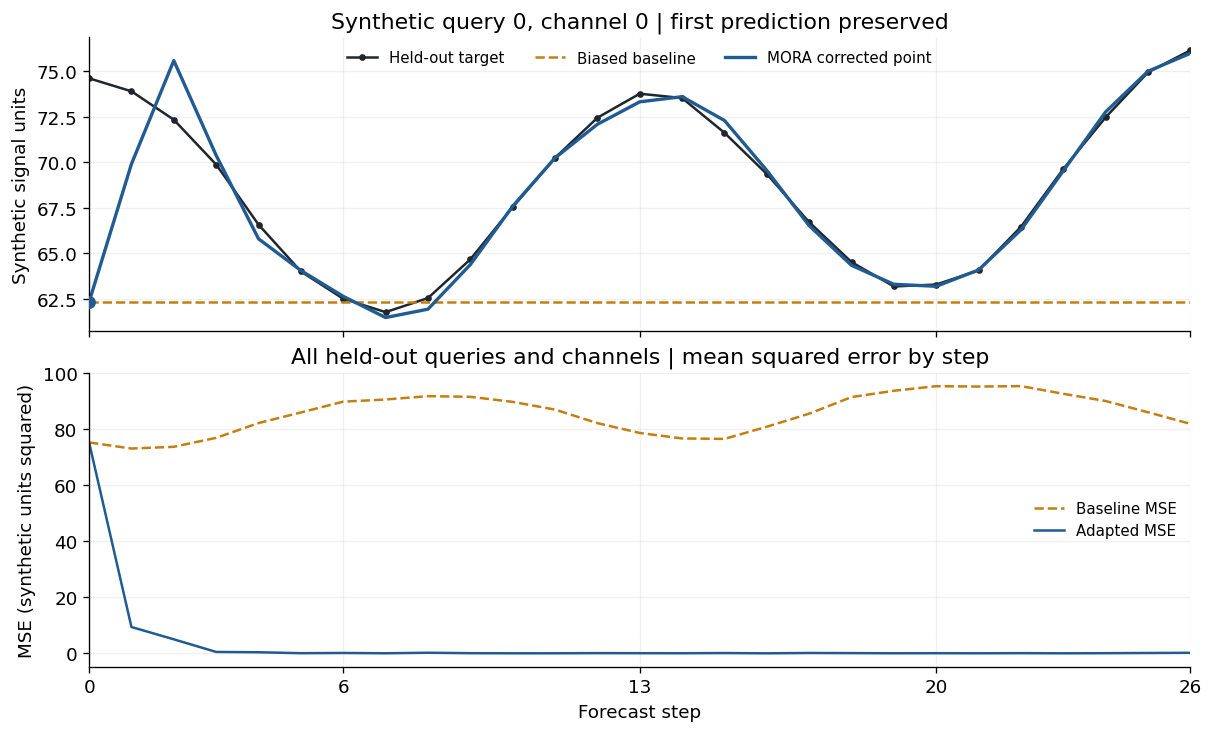

In [11]:
steps = np.arange(config.horizon)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
axes[0].plot(steps, test.target[0, :, 0], color="#20262d", marker="o", markersize=3, label="Held-out target")
axes[0].plot(steps, original_base[0, :, 0], color="#c57e10", linestyle="--", label="Biased baseline")
axes[0].plot(steps, forecast.point[0, :, 0], color="#205b92", linewidth=2, label="MORA corrected point")
axes[0].scatter([0], [forecast.point[0, 0, 0]], color="#205b92", s=45, zorder=5)
axes[0].set(title="Synthetic query 0, channel 0 | first prediction preserved", ylabel="Synthetic signal units")
axes[0].legend(frameon=False, fontsize=9, ncol=3)
axes[1].plot(steps, np.mean((test.target - original_base)**2, axis=(0, 2)),
             color="#c57e10", linestyle="--", label="Baseline MSE")
axes[1].plot(steps, np.mean((test.target - forecast.point)**2, axis=(0, 2)),
             color="#205b92", label="Adapted MSE")
axes[1].set(title="All held-out queries and channels | mean squared error by step",
            xlabel="Forecast step", ylabel="MSE (synthetic units squared)", xticks=[0, 6, 13, 20, 26], xlim=(0, 26))
axes[1].legend(frameon=False, fontsize=9)
for axis in axes:
    axis.grid(alpha=0.18)
plt.show()


## 7. 잘못된 연결과 미래 정답 전달 거부

적합한 기준 모델·단위·채널 순서가 달라지면 같은 보정기를 재사용할 수 없는 계약.
`single_series`에서 다른 부품에 재사용하는 것도 오류.
검증 정답에 맞춘 보정기를 검증 query에 다시 적용해 최종 시험으로 표시하지 않도록 공개 추론은 cutoff 이후만 허용.
실제 0은 유지하지만 NaN은 명시적 창 품질 처리 전까지 거부.


In [12]:
def expect_error(label, operation):
    try:
        operation()
    except (TypeError, ValueError) as error:
        return {"검사": label, "결과": "예상대로 거부", "메시지": str(error)}
    raise AssertionError("거부돼야 하는 입력이 통과했습니다: " + label)

rejection_rows = [
    expect_error("다른 기준 모델", lambda: adapter.predict(replace(test.query, backbone_id="other_checkpoint"))),
    expect_error("다른 단위", lambda: adapter.predict(replace(test.query, scale_id="other_scale"))),
    expect_error("검증 기간 재사용", lambda: adapter.predict(validation.query)),
    expect_error("추론에 정답 전달", lambda: adapter.predict(test.query, target=test.target)),
    expect_error("결측을 0으로 채우지 않음", lambda: replace(test.query, history=np.full_like(test.query.history, np.nan))),
]
display(pd.DataFrame(rejection_rows))


,검사,결과,메시지
0,다른 기준 모델,예상대로 거부,보정기와 기준 모델·채널 순서·단위 계약이 다릅니다.
1,다른 단위,예상대로 거부,보정기와 기준 모델·채널 순서·단위 계약이 다릅니다.
2,검증 기간 재사용,예상대로 거부,공개 predict는 calibration 정답 종료 이후의 query만 허용합니다.
3,추론에 정답 전달,예상대로 거부,MORAAdapter.predict() got an unexpected keywor...
4,결측을 0으로 채우지 않음,예상대로 거부,history에 결측·Inf가 있습니다. v1은 조밀한 관측 창만 지원합니다.


## 8. 검증 정답이 학습 연산에 들어가지 않는지 확인

검증 정답만 크게 바꿔 다시 적합하면 calibration S는 바뀔 수 있으나
coarse ridge, 두 잔차 매핑 K와 reliability G는 그대로여야 하는 조건.
이 셀은 두 매핑·gain과 ridge weight를 직접 비교하는 검사.
별도 단위 테스트에서는 outer held 정답 변경이 자기 2단계 OOF 예측에 영향을 주지 않는지도 확인.


In [13]:
changed_validation = replace(validation, target=validation.target + 10)
candidate = MORAAdapter(config).fit(train, changed_validation)
for field in ("first_mapping", "second_mapping", "first_gain", "second_gain"):
    np.testing.assert_array_equal(getattr(adapter._state, field), getattr(candidate._state, field))
for view in ("absolute", "relative"):
    np.testing.assert_array_equal(getattr(adapter._state.estimator, view).weight,
                                  getattr(candidate._state.estimator, view).weight)
assert not np.array_equal(adapter._state.calibration, candidate._state.calibration)
calibration_isolated = True
print("학습 coarse·K·G 동일 / 검증 scale 변경: 확인")


학습 coarse·K·G 동일 / 검증 scale 변경: 확인


## 9. 저장과 재로딩

학습 상태는 C-order FP64로 고정해 현재 환경에서 저장 전후 연산 경로도 동일하게 유지.
NPZ에는 숫자 배열과 UTF-8 JSON만 저장하고 pickle 로딩은 허용하지 않는 방식.
SHA-256은 무결성 검사이며 공격자 인증이나 전자서명과 구분.
신뢰할 수 있는 로컬 산출물에 사용하는 계약.

아래 파일은 임시 디렉토리 안에서만 만들고 정리.
계속 보관할 실험은 별도 CLI의 새로운 `--output-dir` 지정 필요.


In [14]:
with tempfile.TemporaryDirectory(prefix="mora-notebook-") as directory:
    path = adapter.save(Path(directory) / "adapter.npz")
    restored = MORAAdapter.load(path)
    replay = restored.predict(test.query)
    np.testing.assert_array_equal(replay.point, forecast.point)
    save_load_identical = True
    print("저장 전후 점예측 완전 일치:", save_load_identical)
    print("저장 형식: NPZ + JSON / pickle 미사용")


저장 전후 점예측 완전 일치: True
저장 형식: NPZ + JSON / pickle 미사용


## 이번 실행의 확인 결과

아래 표는 실제 실행한 셀에서 확인한 결과.
원본 모델·원본 데이터·DB에는 변경을 가하지 않은 실습.
첫 위치 오차, 미지원 기능과 합성 baseline의 편향을 숨기지 않고 결과를 해석하는 기준.


In [15]:
checks = [
    ("구간 평균·직교 기저", np.allclose(U.T @ U, np.eye(config.correction_rank))),
    ("첫 예측값 보존", np.array_equal(forecast.point[:, 0], original_base[:, 0])),
    ("기준 예측 입력 유지", np.array_equal(original_base, test.query.backbone_prediction)),
    ("합성 시험 MSE 감소", adapted_metrics["mse"] < baseline_metrics["mse"]),
    ("잘못된 연결·정답 전달 거부", len(rejection_rows) == 5),
    ("검증 정답과 학습 파라미터 분리", calibration_isolated),
    ("저장·재로딩 예측 일치", save_load_identical),
]
assert all(bool(result) for _, result in checks)
display(pd.DataFrame([{"검사": name, "통과": bool(result)} for name, result in checks]))
print("구현:", forecast.metadata["implementation"], "/ 실제 데이터 사용: 없음")


,검사,통과
0,구간 평균·직교 기저,True
1,첫 예측값 보존,True
2,기준 예측 입력 유지,True
3,합성 시험 MSE 감소,True
4,잘못된 연결·정답 전달 거부,True
5,검증 정답과 학습 파라미터 분리,True
6,저장·재로딩 예측 일치,True


구현: paper_independent_v1 / 실제 데이터 사용: 없음


## 다음 작업과 참고

**실제 기준 모델 연결 · 다음 검증**

Chronos2 등에서 고정된 가중치로 과거 입력과 기준 점예측을 생성하고,
실제 단위·채널·부품 범위를 맞춘 독립 실험으로 연결할 단계.
이 노트북이 기존 모델의 추론 API를 자동 변경하는 기능은 없는 상태.

**실데이터 적합 · 별도 승인 대상**

실제 수량 품질, 부품별/공용 scope, OOF 생산 증적, 학습·검증·시험 cutoff를 먼저 확정할 대상.
기존 Chronos2의 70:15:15 부품 분할을 자동으로 변경하거나 이식하지 않는 기준.

**후속 수식 확장 · 별도 구현**

Harmonic template·factorized estimator·설정 후보 탐색과 실제 예측 불확실성의 보정 검증은 남은 범위.
저자 코드와의 동등성 또는 논문 benchmark 성능 재현을 완료한 것으로 표시하지 않는 기준.

참고 자료:

- [구현 설명](../README.md), [출처·구현 선택과 차이](../SOURCE.md)
- [실제 보정 수식](../native/stagewise.py), [OOF·적합](../fitting.py), [저장 계약](../checkpoints.py)
- [단위 테스트](../../../../../tests/test_mora_adapter.py)
- [MORA 논문 v2](https://arxiv.org/abs/2611.15413v2)
